<a href="https://colab.research.google.com/github/srcorreia3001/analise_de_vendas_de_calcados/blob/main/analise_vendas_de_calcados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

print("---Gerando Banco de Dados pata Loja de calçados---")
#Vamos fixar uma semente para que os numeros sejam sempre os mesmos toda vez que rodaro codigo.
np.random.seed(42)

#Parametro da loja
total_vendas = 200 # Aqui vamos gerar 200 produtos vendidos
categorias = ['Tênis Esportivo','Bota de Couro','Sandália','Sapato Social']
tamanhos = list(range(34,45)) # Tamanho de 34 a 45j

#Gerando as colunas
#ID de transação, usamos um intervalo de menor de 200 para forçar que alguns Ids se repitam
#Similando que a pessoa comprou mais de um calçado no mesmo recibo.
ids_transacao = np.random.randint(1000,1150,size=total_vendas)

#Datas de vendas espalhadas ao longo de um ano
datas_base = pd.date_range(start='2023-01-01', end='2023-12-31')
datas_vendas = np.random.choice(datas_base, size=total_vendas)

#Categoria (Tênis vende mais sapato social vende menos)
prob_categorias =[0.40,0.20,0.25,0.15]
produtos_vendidos = np.random.choice(categorias,size=total_vendas,p=prob_categorias)

#Distribuição de tamanhos
#Tamanhos centrais de 38 a 41 com alta probabilidade de vendas
prob_tamanhos = [0.02,0.03,0.05,0.10,0.20,0.20,0.15,0.15,0.05,0.03,0.02]
tamanhos_vendidos = np.random.choice(tamanhos,size=total_vendas, p=prob_tamanhos)

#Custo de preço baseado na categoria do calçado.
tabela_custos = {'Tênis Esportivo':80.00, 'Bota de Couro':150.0,'Sandália':40.0,'Sapato Social':120.0}
tabela_precos = {'Tênis Esportivo':199.90, 'Bota de Couro':349.90,'Sandália':99.90,'Sapato Social':289.90}

custo_lista = [tabela_custos[p] for p in produtos_vendidos]
preco_lista = [tabela_precos[p] for p in produtos_vendidos]

#Montando a tabela inicial DataFrame
df = pd.DataFrame({
    'ID_Transacao': ids_transacao,
    'Data_Venda':datas_vendas,
    'Categoria_Produto':produtos_vendidos,
    'Tamanho':tamanhos_vendidos,
    'Custo_Fabrica':custo_lista,
    'Preco_Venda':preco_lista
})

#Ordenando vendas pela data de forma cronologica
df = df.sort_values(by='Data_Venda').reset_index(drop=True)

print("Lista Criada com 200 vendas com sucesso.\n")

#INSPECIONANDO OS DADOS
print("--- As primeiras 5 linhas---")
print(df.head())

print("\n---Informações Estruturais---")
print(df.info())

---Gerando Banco de Dados pata Loja de calçados---
Lista Criada com 200 vendas com sucesso.

--- As primeiras 5 linhas---
   ID_Transacao Data_Venda Categoria_Produto  Tamanho  Custo_Fabrica  \
0          1095 2023-01-01   Tênis Esportivo       38           80.0   
1          1087 2023-01-02          Sandália       44           40.0   
2          1123 2023-01-04          Sandália       38           40.0   
3          1080 2023-01-05          Sandália       40           40.0   
4          1128 2023-01-06     Bota de Couro       37          150.0   

   Preco_Venda  
0        199.9  
1         99.9  
2         99.9  
3         99.9  
4        349.9  

---Informações Estruturais---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   ID_Transacao       200 non-null    int64         
 1   Data_Venda         200 non-null    dat

---CRIAÇÃO DE METRICAS E ANÁLISE DE GRADE---
Colunas 'Lucro Bruto' e 'Mes' Criadas com Sucesso!

---ANÁLISANDO O VOLUME DE VENDAS POR TAMANHO---
    Tamanho  Quantidade_Vendida  Percentual_%
0        38                  43          21.5
1        39                  42          21.0
2        37                  32          16.0
3        41                  26          13.0
4        40                  24          12.0
5        36                   9           4.5
6        42                   8           4.0
7        44                   6           3.0
8        35                   5           2.5
9        43                   4           2.0
10       34                   1           0.5


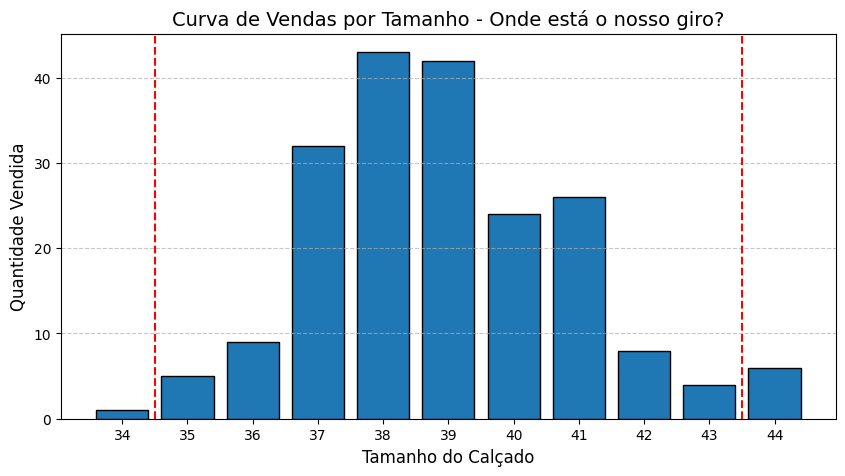

In [2]:
import matplotlib.pyplot as plt

print("---CRIAÇÃO DE METRICAS E ANÁLISE DE GRADE---")
#Criando colunas que geram valor para o negocio
#Calculando o lucro bruto unitario (O quanto sobra após pagar fabricante)
df['Lucro_Bruto'] = df['Preco_Venda'] - df['Custo_Fabrica']

#Extraindo apenas o mes da data da venda isso sera importante quando fizermos a sazonalidade
df['Mes'] = df['Data_Venda'].dt.month

print("Colunas 'Lucro Bruto' e 'Mes' Criadas com Sucesso!\n")

#ANÁLISE DE GRADE DE TAMANHO - O ESTOQUE
print("---ANÁLISANDO O VOLUME DE VENDAS POR TAMANHO---")

#Agrupando os dados, quantas vezes cada tamanho aparece nos recibos
vendas_por_tamanho = df.groupby('Tamanho')['ID_Transacao'].count().reset_index()
vendas_por_tamanho.columns = ['Tamanho', 'Quantidade_Vendida']

#Calculando o percentual que cada tamanho representa no total de vendas
total_produtos = vendas_por_tamanho['Quantidade_Vendida'].sum()
vendas_por_tamanho['Percentual_%'] = (vendas_por_tamanho['Quantidade_Vendida']/total_produtos * 100).round(1)

#Ordenando a tabela para o tamanho que mais vendeu para o que menos vendeu
tabela_tamanho_ordenada = vendas_por_tamanho.sort_values(by='Quantidade_Vendida', ascending=False).reset_index(drop=True)
print(tabela_tamanho_ordenada)

#GERANDO OS GRAFICOS
plt.figure(figsize=(10,5))

#Usamos as categorias ordenadas por tamanho (do 34 a 44) para o grafico fazer sentido cronologico
plt.bar(vendas_por_tamanho['Tamanho'].astype(str),vendas_por_tamanho['Quantidade_Vendida'],color='#1f77b4', edgecolor='black')

plt.title('Curva de Vendas por Tamanho - Onde está o nosso giro?',fontsize=14)
plt.xlabel('Tamanho do Calçado',fontsize=12)
plt.ylabel('Quantidade Vendida',fontsize=12)
plt.grid(axis='y',linestyle='--',alpha=0.7)

#Destacando os tamanhos problematicos
plt.axvline(x=0.5,color='red',linestyle='--',label='Risco de Encalhe (Pequenos)')
plt.axvline(x=9.5,color='red',linestyle='--',label='Risco de Enacalhe (Grande)')

plt.show()


---Análise de Sazonalidade e Timing---


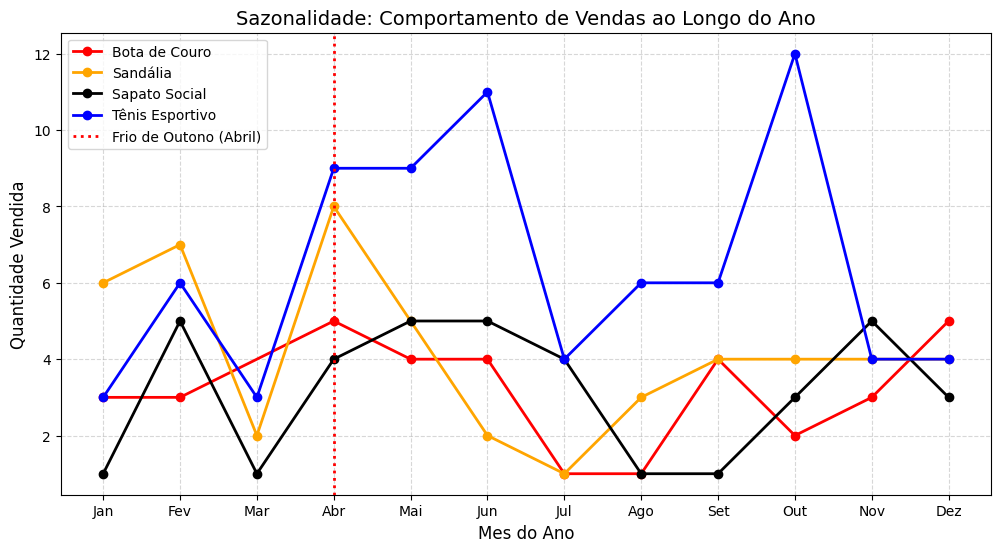

In [3]:
#AGORA FAREMOS A ANÁLISE DE SAZONALIDADE
print("\n---Análise de Sazonalidade e Timing---")

#Preparação dos dados: Vamos agruṕar as vendas por mes e por categoria
vendas_mensais = df.groupby(['Mes','Categoria_Produto'])['ID_Transacao'].count().reset_index()
vendas_mensais.columns =['Mes','Categoria_Produto','Quantidade_Vendida']

#Gerar grafico de linhas - A evolução ao longo dos meses
plt.figure(figsize=(12,6))

#Definimos cores especificas para fazerem sentido visualmente
cores = {'Tênis Esportivo': 'blue','Bota de Couro':'red','Sandália':'orange','Sapato Social':'black'}

#Vamos desenhar uma linha para cada categoria de calçado
for categoria in vendas_mensais['Categoria_Produto'].unique():
  dados_categoria = vendas_mensais[vendas_mensais['Categoria_Produto']== categoria]
  plt.plot(dados_categoria['Mes'],dados_categoria['Quantidade_Vendida'],
           marker='o', linewidth=2, label=categoria, color=cores[categoria])

#Formaçao de grafico para apresentaçao de negocios
plt.title('Sazonalidade: Comportamento de Vendas ao Longo do Ano',fontsize=14)
plt.xlabel('Mes do Ano', fontsize=12)
plt.ylabel('Quantidade Vendida', fontsize=12)

#Substituir os numeros de 1 a 12 pelos nomes dos meses no eixo X
plt.xticks(range(1,13),['Jan','Fev','Mar','Abr','Mai','Jun','Jul','Ago','Set','Out','Nov','Dez'])

#Adicionar uma grelha para facilitar a leitura dos pontos
plt.grid(True,linestyle='--',alpha=0.5)
plt.legend(title='Categorias',loc='upper right')

#Destacar o insight das transiçoes de estação
plt.axvline(x=4, color='red',linestyle=':', linewidth=2, label='Frio de Outono (Abril)')
plt.legend()

plt.show()

In [4]:
print("\n---ANÁLISE DE CESTAS DE COMPRAS (CROSS-SELLING)---")

#Vamos isolar as compras agrupadas
#Vamos contas quantos produtos existem dentro do mesmo ID de transacao
itens_por_recibo = df.groupby('ID_Transacao')['Categoria_Produto'].count().reset_index()
itens_por_recibo.columns = ['ID_Transacao','Quantidade_Itens']

#Filtrando os recibos onde os clientes compraram dois produtos ou mais
recibos_multiplos = itens_por_recibo[itens_por_recibo['Quantidade_Itens'] > 1]['ID_Transacao']

print(f"Total de faturas emitidas no ano: {df['ID_Transacao'].nunique()}")
print(f"Faturas com mais de 1 item (Venda Cruzada): {len(recibos_multiplos)}")

#DESCOBRIR OS PADROES DE COMPRA
#Vou filtrar nossa base de dados original para manter apenas as linhas dos recibos
vendas_conjuntas = df[df['ID_Transacao'].isin(recibos_multiplos)]

#Agrupamos as categorias vendidas na mesma fatura
cestas = vendas_conjuntas.groupby('ID_Transacao')['Categoria_Produto'].apply(lambda x: ' + '.join(sorted(x))).reset_index()
cestas.columns = ['ID_Transacoes', 'Combinacao_Produtos']

#Contamos quais são as combinações de exatas que mais se repetem
top_combinacoes = cestas['Combinacao_Produtos'].value_counts().reset_index()
top_combinacoes.columns = ['Combinacao_Produtos', 'Frequencia de Compras']

print("\n---Top 5 Combinações de Produtos no Mesmo Recibo---")
print(top_combinacoes.head())

#SOLUÇÃO DIRETA DE NEGOCIO O QUE O SENHOR GESTOR PODE FAZER COM ISSO!
print("\n RECOMENDAÇÃO FINAL PARA O GESTOR:")
print("Implementar campanhas de da zona de pagamentos.Se o 'Tênis Esportivo + Sandália' é uma combinação frequente,ofereça 20% de desconto no segundo par para forçar essa compra conjunta em clientes que levam apenas um item.")


---ANÁLISE DE CESTAS DE COMPRAS (CROSS-SELLING)---
Total de faturas emitidas no ano: 104
Faturas com mais de 1 item (Venda Cruzada): 60

---Top 5 Combinações de Produtos no Mesmo Recibo---
                 Combinacao_Produtos  Frequencia de Compras
0    Sapato Social + Tênis Esportivo                      9
1           Bota de Couro + Sandália                      6
2  Tênis Esportivo + Tênis Esportivo                      6
3         Sandália + Tênis Esportivo                      5
4    Bota de Couro + Tênis Esportivo                      5

 RECOMENDAÇÃO FINAL PARA O GESTOR:
Implementar campanhas de da zona de pagamentos.Se o 'Tênis Esportivo + Sandália' é uma combinação frequente,ofereça 20% de desconto no segundo par para forçar essa compra conjunta em clientes que levam apenas um item.


In [5]:
print("\n----DEMONSTRAÇÃO DO RESULTADO DO EXERCICIO (DRE)---")

#Vamos fazer primeiro os calculos financeiros ja consolidados
faturamento_bruto = df['Preco_Venda'].sum()
custo_total_cmv =df['Custo_Fabrica'].sum()
lucro_bruto_total = df['Lucro_Bruto'].sum()
margem_bruta_pct = (lucro_bruto_total / faturamento_bruto) * 100
total_pares_vendidos = len(df)
ticket_medio_produto = df['Preco_Venda'].mean()

#Criando um quadro oficial de DRE
dre_dados = {
    'Linha da DRE':[
        '1.Receita Bruta de Vendas (Faturamento)',
        '2.(-) Custo de Mercadorias Vendidas (CMV)',
        '3.(=) Lucro Bruto Consolidado',
        '4.Margem de Lucro Bruto (%)',
        '5.Ticket Médio por Item Vendido',
        '6.Total de Volume Comercializado'
    ],
    'Valor Consolidado':[
        f"R${faturamento_bruto:,.2f}",
        f"R${custo_total_cmv:,.2f}",
        f"R${lucro_bruto_total:,.2f}",
        f"{margem_bruta_pct:.2f}%",
        f"R${ticket_medio_produto:,.2f}",
        f"{total_pares_vendidos}pares"
    ]
}

df_dre = pd.DataFrame(dre_dados)

print("\n=====================================================================")
print("              DRE SIMPLIFICADA - DESEMPENHO ANUAL DA LOJA             ")
print("======================================================================")
print(df_dre.to_string(index=False))
print("======================================================================")


----DEMONSTRAÇÃO DO RESULTADO DO EXERCICIO (DRE)---

              DRE SIMPLIFICADA - DESEMPENHO ANUAL DA LOJA             
                             Linha da DRE Valor Consolidado
  1.Receita Bruta de Vendas (Faturamento)       R$43,650.00
2.(-) Custo de Mercadorias Vendidas (CMV)       R$17,970.00
            3.(=) Lucro Bruto Consolidado       R$25,680.00
              4.Margem de Lucro Bruto (%)            58.83%
          5.Ticket Médio por Item Vendido          R$218.25
         6.Total de Volume Comercializado          200pares
